# MobileNetV3-Large — bệnh/trạng thái lá cà chua

Huấn luyện bằng hosted GPU runtime **Google Colab**. Không dùng kernel Windows/local.
Dataset giải nén trong `/content`, checkpoint/báo cáo lưu trên Google Drive.
**Run All không tự chạy full training/Test.** Backend tiếp tục dùng Mock AI.


## 1. Chuẩn bị Colab

Đóng gói bằng `scripts/package-colab.ps1` trên Drive (không train).
Upload `aiot-ml-colab.zip` và `plantvillage.zip` vào `MyDrive/aiot-plant-care/`.
Mở notebook trên Colab, chọn runtime Python 3.12 + GPU, chạy từ đầu và cho phép mount Drive.
Nếu bootstrap yêu cầu restart session sau cài dependency, restart rồi chạy lại từ đầu.


In [1]:
from pathlib import Path
import os
import sys
import hashlib
import zipfile
import importlib

if sys.platform != "linux":
    raise RuntimeError("Chọn hosted runtime Google Colab; không dùng kernel Windows/local.")
try:
    from google.colab import drive
except ImportError as error:
    raise RuntimeError("Notebook yêu cầu hosted runtime Google Colab.") from error
drive.mount("/content/drive")
DRIVE_ROOT = Path(os.getenv("COLAB_DRIVE_ROOT", "/content/drive/MyDrive/aiot-plant-care"))
SOURCE_ZIP = DRIVE_ROOT / "aiot-ml-colab.zip"
if not SOURCE_ZIP.is_file():
    raise FileNotFoundError(f"Upload ZIP mã nguồn trước: {SOURCE_ZIP}")
with SOURCE_ZIP.open("rb") as stream:
    source_hash = hashlib.file_digest(stream, "sha256").hexdigest()
ML_ROOT = Path("/content") / f"aiot-ml-{source_hash[:12]}"
ready = ML_ROOT / ".ready"
if not ready.exists():
    if ML_ROOT.exists() and any(ML_ROOT.iterdir()):
        raise RuntimeError("Source giải nén dở; dùng runtime mới, không trộn source.")
    with zipfile.ZipFile(SOURCE_ZIP) as archive:
        if sum(item.file_size for item in archive.infolist()) > 50 * 1024**2:
            raise ValueError("Source ZIP quá lớn; không đóng kèm dataset/weights.")
        for item in archive.infolist():
            target = (ML_ROOT / item.filename).resolve()
            if (not target.is_relative_to(ML_ROOT) or chr(92) in item.orig_filename
                    or (item.external_attr >> 16) & 0o170000 == 0o120000):
                raise ValueError("Source ZIP có đường dẫn không hợp lệ hoặc symlink")
        archive.extractall(ML_ROOT)
    ready.write_text(source_hash, encoding="utf-8")
sys.path.insert(0, str(ML_ROOT))
if "colab_runtime" in sys.modules and Path(sys.modules["colab_runtime"].__file__).resolve() != ML_ROOT / "colab_runtime.py":
    raise RuntimeError("Source ZIP changed: restart session before continuing.")
colab_runtime = importlib.import_module("colab_runtime")
prepare_runtime = colab_runtime.prepare_runtime
extract_zip_once = colab_runtime.extract_zip_once

INSTALL_DEPS = True  # Nếu thư viện đã đúng lock, không cài lại.
RUNTIME_INFO = prepare_runtime(ML_ROOT, require_gpu=True, install=INSTALL_DEPS)
CODE_ROOT = ML_ROOT / "leaf-disease"
sys.path.insert(0, str(CODE_ROOT))
os.chdir(CODE_ROOT)
print("Kernel Colab:", sys.executable, "| Source SHA256:", source_hash)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
{
  "python": "3.12.13",
  "torch": "2.11.0+cu128",
  "torchvision": "0.26.0+cu128",
  "cuda": "12.8",
  "device": "Tesla T4"
}
Kernel Colab: /usr/bin/python3 | Source SHA256: 5aeff8959d22dca2002dc7fce54b37ae19e2f9943fed5a5d9a1909bc453e0695


## 2. Xác nhận GPU Colab

Kiểm tra GPU thực tế được cấp; không giả định luôn có T4. Giữ Torch/CUDA của runtime.
Batch 32, workers 2 là cấu hình khởi đầu; giảm batch khi OOM và tạo run mới.
Checkpoint lưu trong `MyDrive/aiot-plant-care/leaf-runs/`.


In [2]:
import importlib.metadata
import json
import platform
import numpy as np
import PIL
import sklearn
import torch
import torchvision
from packaging.version import Version
from datetime import datetime, timezone
from IPython.display import display, Image as DisplayImage
from leaf_training.data import (CLASSES, discover_classes, audit_dataset, split_records,
                                subset_for_smoke, write_json)
from leaf_training.train import TrainConfig, train, evaluate
from leaf_training.inference import Predictor

for package, loaded in [("numpy", np.__version__), ("Pillow", PIL.__version__),
                        ("scikit-learn", sklearn.__version__)]:
    if loaded != importlib.metadata.version(package):
        raise RuntimeError(f"Restart kernel: {package} đang giữ phiên bản cũ trong bộ nhớ")
if Version(torch.__version__.split("+")[0]) < Version("2.6"):
    raise RuntimeError("Cần torch >=2.6; chọn runtime Colab tương thích.")
print("Python:", platform.python_version(), "torch:", torch.__version__,
      "torchvision:", torchvision.__version__, "CUDA:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())
if not torch.cuda.is_available():
    raise RuntimeError("CUDA không khả dụng; chọn GPU runtime Colab.")
print("GPU:", torch.cuda.get_device_name(0))
print("VRAM GB:", round(torch.cuda.get_device_properties(0).total_memory / 2**30, 2))

RUNS_ROOT = Path(os.getenv("LEAF_OUTPUT_ROOT", str(DRIVE_ROOT / "leaf-runs")))
RUNS_ROOT.mkdir(parents=True, exist_ok=True)
SESSION_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
AUDIT_DIR = RUNS_ROOT / f"audit-{SESSION_ID}"
FULL_RUN = None
print("Checkpoint và báo cáo:", RUNS_ROOT)


Python: 3.12.13 torch: 2.11.0+cu128 torchvision: 0.26.0+cu128 CUDA: 12.8
CUDA available: True
GPU: Tesla T4
VRAM GB: 14.56
Checkpoint và báo cáo: /content/drive/MyDrive/aiot-plant-care/leaf-runs


## 3. Dữ liệu trên Colab

Mặc định giải nén `plantvillage.zip` từ Drive sang ổ đĩa runtime để giảm I/O Drive.
Có thể chọn `DATA_SOURCE="kaggle"`; nếu cần đăng nhập, dùng `kagglehub.login()` riêng,
không ghi token vào notebook. Ghim handle `/versions/N` sau lần tải đầu để tái lập.


In [3]:
import kagglehub

DATA_SOURCE = "drive_zip"
KAGGLE_HANDLE = "charuchaudhry/plantvillage-tomato-leaf-dataset"
if DATA_SOURCE == "drive_zip":
    DATA_ROOT = extract_zip_once(DRIVE_ROOT / "plantvillage.zip", Path("/content/aiot-data/plantvillage"))
elif DATA_SOURCE == "kaggle":
    DATA_ROOT = Path(kagglehub.dataset_download(KAGGLE_HANDLE))
else:
    raise ValueError("DATA_SOURCE phải là drive_zip hoặc kaggle")
files, folders = discover_classes(DATA_ROOT)
for folder in folders:
    print(folder)
print("Root:", DATA_ROOT, "| Số ảnh:", len(files))
PROVENANCE = {
    "dataset_url": "https://www.kaggle.com/datasets/charuchaudhry/plantvillage-tomato-leaf-dataset",
    "handle": KAGGLE_HANDLE if DATA_SOURCE == "kaggle" else None,
    "source": DATA_SOURCE, "resolved_root": str(DATA_ROOT), "code_sha256": source_hash,
    "observed_at": datetime.now(timezone.utc).isoformat(),
}
write_json(AUDIT_DIR / "source.json", PROVENANCE)


{'folder': 'plantvillage/Tomato___Bacterial_spot', 'class_name': 'Tomato___Bacterial_spot', 'images': 1702}
{'folder': 'plantvillage/Tomato___Early_blight', 'class_name': 'Tomato___Early_blight', 'images': 800}
{'folder': 'plantvillage/Tomato___Late_blight', 'class_name': 'Tomato___Late_blight', 'images': 1527}
{'folder': 'plantvillage/Tomato___Leaf_Mold', 'class_name': 'Tomato___Leaf_Mold', 'images': 761}
{'folder': 'plantvillage/Tomato___Septoria_leaf_spot', 'class_name': 'Tomato___Septoria_leaf_spot', 'images': 1417}
{'folder': 'plantvillage/Tomato___Spider_mites Two-spotted_spider_mite', 'class_name': 'Tomato___Spider_mites Two-spotted_spider_mite', 'images': 1341}
{'folder': 'plantvillage/Tomato___Target_Spot', 'class_name': 'Tomato___Target_Spot', 'images': 1123}
{'folder': 'plantvillage/Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'class_name': 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'images': 4286}
{'folder': 'plantvillage/Tomato___Tomato_mosaic_virus', 'class_name': 'Tomato___To

## 4. Kiểm tra ảnh lỗi, trùng và gần trùng

Audit đọc toàn bộ ảnh trước chia tập, không xóa ảnh gốc. Nhóm mâu thuẫn nhãn được cách ly.
Nếu có metadata cùng lá, cung cấp CSV `path,leaf_id` với path tương đối DATA_ROOT, dùng `/`.
pHash không bảo đảm phát hiện cùng lá khác góc/ánh sáng. Xem báo cáo và các cặp ảnh bằng mắt;
chưa có leaf ID thì chưa thể khẳng định độc lập theo chiếc lá.


Kiểm tra ảnh:   0%|          | 0/14529 [00:00<?, ?it/s]

Gom ảnh trùng/gần trùng:   0%|          | 0/14529 [00:00<?, ?it/s]

{'raw_count': 14529, 'valid_count': 14529, 'clean_count': 14510, 'leaf_metadata_count': 0}
Ảnh lỗi: 0 | Ảnh loại: 19 | Nhóm trùng/gần trùng: 45
Báo cáo đầy đủ: /content/drive/MyDrive/aiot-plant-care/leaf-runs/audit-20261015T031223_837040Z/audit.json


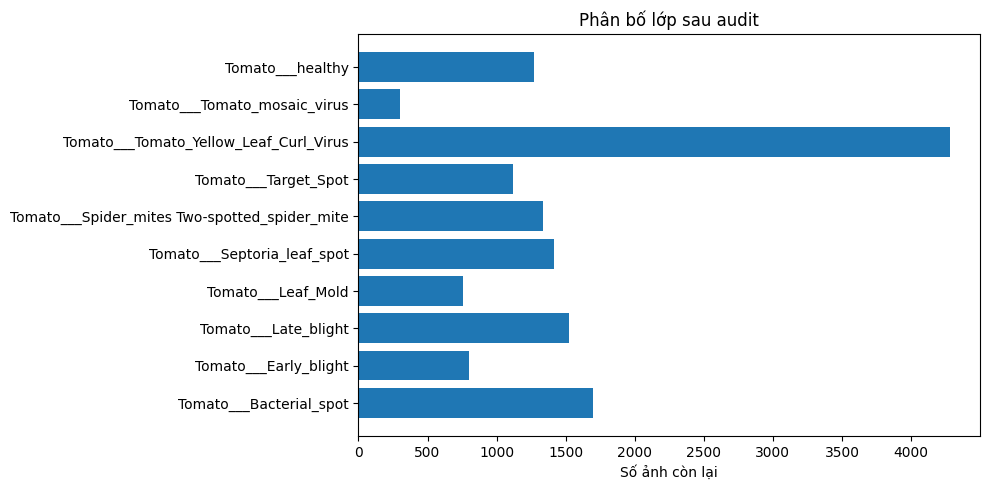

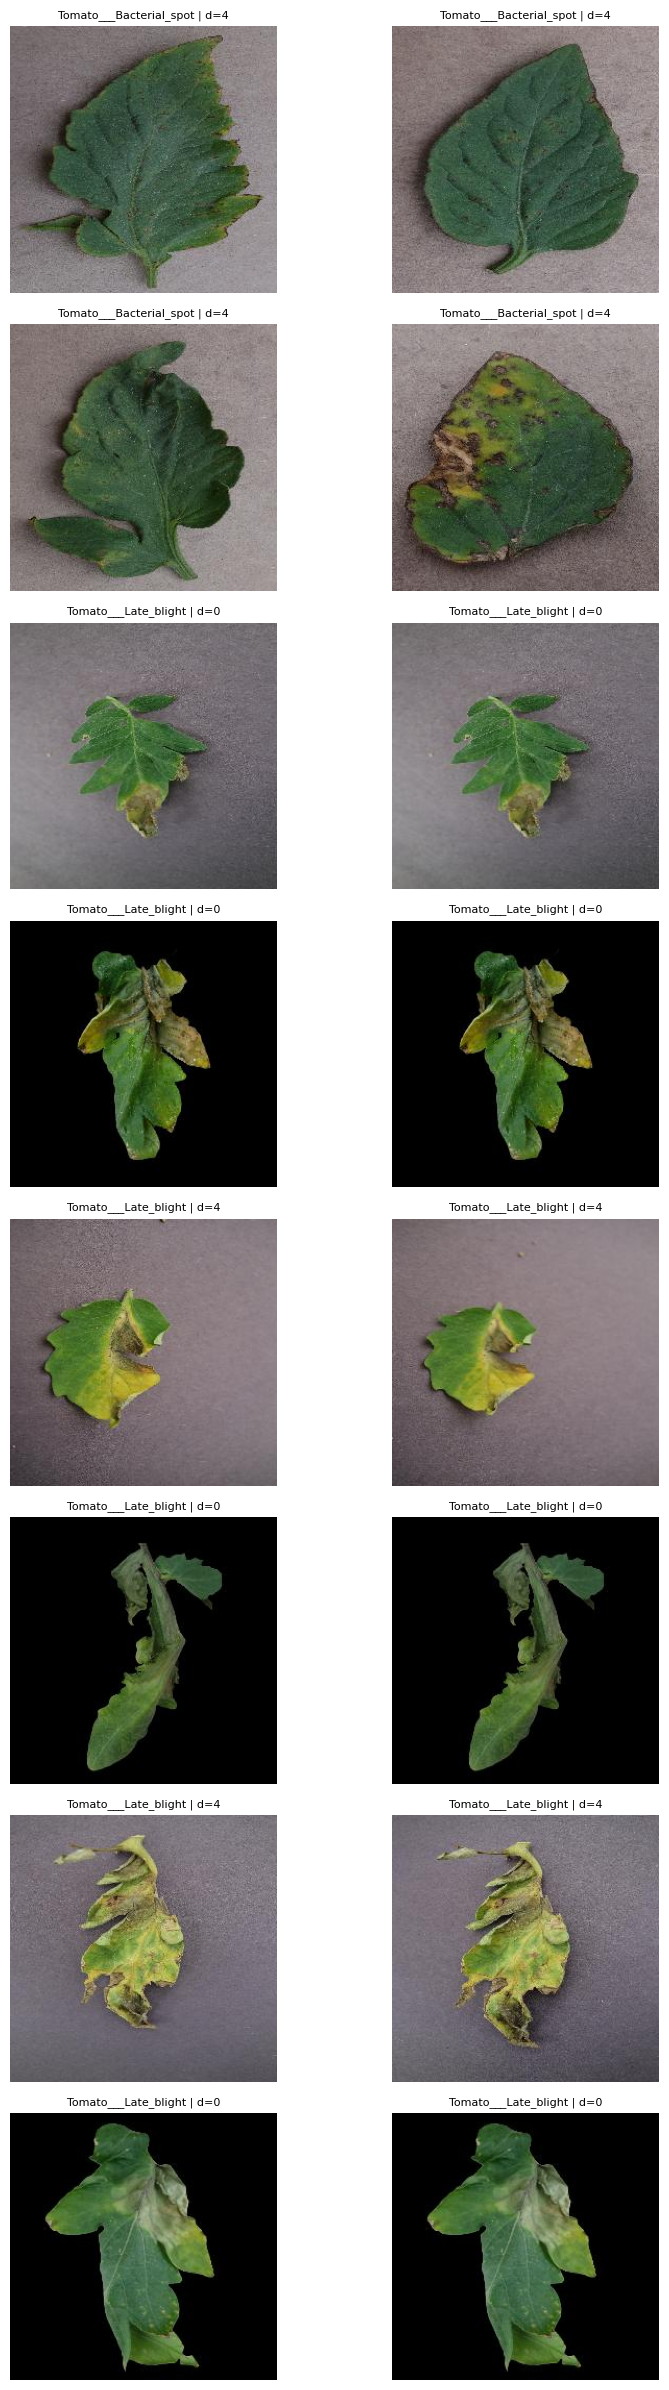

In [4]:
import matplotlib.pyplot as plt
from leaf_training.model import open_rgb

LEAF_GROUPS_CSV = None
PHASH_DISTANCE = 4
clean_records, audit = audit_dataset(DATA_ROOT, AUDIT_DIR, distance=PHASH_DISTANCE,
                                     leaf_groups_csv=LEAF_GROUPS_CSV)
print({key: audit[key] for key in ("raw_count", "valid_count", "clean_count", "leaf_metadata_count")})
print("Ảnh lỗi:", len(audit["corrupt"]), "| Ảnh loại:", len(audit["excluded"]),
      "| Nhóm trùng/gần trùng:", len(audit["groups"]))
print("Báo cáo đầy đủ:", AUDIT_DIR / "audit.json")

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(CLASSES, [audit["class_counts"].get(name, 0) for name in CLASSES])
ax.set(xlabel="Số ảnh còn lại", title="Phân bố lớp sau audit")
plt.tight_layout()
plt.show()

pairs = audit["near_pairs"][:8]  # Mẫu hiển thị; đọc audit.json để rà soát đầy đủ.
if pairs:
    fig, axes = plt.subplots(len(pairs), 2, figsize=(9, 3 * len(pairs)), squeeze=False)
    for axes_row, pair in zip(axes, pairs):
        for ax, key in zip(axes_row, ("a", "b")):
            ax.imshow(open_rgb(DATA_ROOT / pair[key]))
            ax.set_title(f"{Path(pair[key]).parent.name} | d={pair['distance']}", fontsize=8)
            ax.axis("off")
    plt.tight_layout()
    plt.show()


## 5. Chia Train / Validation / Test

Seed 42, tỷ lệ 70/15/15 theo nhóm từng lớp; số ảnh có thể lệch do kích thước nhóm khác nhau.
Manifest và fingerprint lưu trong Google Drive. Ảnh cùng nhóm/hash/leaf_id không được ở khác tập.
Augmentation chỉ dùng Train. Trọng số cân bằng lớp chỉ tính từ Train.


In [5]:
from collections import Counter
records, split_fingerprint = split_records(clean_records, AUDIT_DIR, seed=42)
for split in ("train", "val", "test"):
    rows = [r for r in records if r["split"] == split]
    print(split, "ảnh:", len(rows), "nhóm:", len({r["group_id"] for r in rows}),
          "phân bố:", dict(Counter(r["class_name"] for r in rows)))
print("Fingerprint:", split_fingerprint)


train ảnh: 10156 nhóm: 10136 phân bố: {'Tomato___Bacterial_spot': 1190, 'Tomato___Early_blight': 560, 'Tomato___Late_blight': 1065, 'Tomato___Leaf_Mold': 532, 'Tomato___Septoria_leaf_spot': 991, 'Tomato___Spider_mites Two-spotted_spider_mite': 938, 'Tomato___Target_Spot': 785, 'Tomato___Tomato_Yellow_Leaf_Curl_Virus': 2995, 'Tomato___Tomato_mosaic_virus': 209, 'Tomato___healthy': 891}
val ảnh: 2178 nhóm: 2171 phân bố: {'Tomato___Bacterial_spot': 256, 'Tomato___Early_blight': 120, 'Tomato___Late_blight': 229, 'Tomato___Leaf_Mold': 114, 'Tomato___Septoria_leaf_spot': 212, 'Tomato___Spider_mites Two-spotted_spider_mite': 200, 'Tomato___Target_Spot': 168, 'Tomato___Tomato_Yellow_Leaf_Curl_Virus': 645, 'Tomato___Tomato_mosaic_virus': 45, 'Tomato___healthy': 189}
test ảnh: 2176 nhóm: 2171 phân bố: {'Tomato___Bacterial_spot': 255, 'Tomato___Early_blight': 120, 'Tomato___Late_blight': 228, 'Tomato___Leaf_Mold': 114, 'Tomato___Septoria_leaf_spot': 212, 'Tomato___Spider_mites Two-spotted_spider_

## 6. Smoke 1 epoch — ImageNet pretrained, tối đa 80 Train + 80 Validation

Kiểm tra training classifier, metrics Validation, checkpoint, load và inference.
Sau đó thử một batch backprop qua backbone fine-tuning. Không đọc Test.
Smoke metrics không phải chất lượng mô hình cuối. Nếu OOM, giảm batch và dùng tên run mới.


Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 139MB/s]


Epoch 1/1 (head): loss=2.3423; val_loss=1.9990; val_macro_f1=0.3443
{
  "loss": 1.998796033859253,
  "accuracy": 0.3625,
  "precision_macro": 0.5419785076501996,
  "recall_macro": 0.3625,
  "macro_f1": 0.34427446508091664
}
{
  "Tomato___Bacterial_spot": {
    "precision": 0.3684210526315789,
    "recall": 0.875,
    "f1-score": 0.5185185185185185,
    "support": 8.0
  },
  "Tomato___Early_blight": {
    "precision": 0.25,
    "recall": 0.25,
    "f1-score": 0.25,
    "support": 8.0
  },
  "Tomato___Late_blight": {
    "precision": 0.17391304347826086,
    "recall": 0.5,
    "f1-score": 0.25806451612903225,
    "support": 8.0
  },
  "Tomato___Leaf_Mold": {
    "precision": 1.0,
    "recall": 0.125,
    "f1-score": 0.2222222222222222,
    "support": 8.0
  },
  "Tomato___Septoria_leaf_spot": {
    "precision": 1.0,
    "recall": 0.375,
    "f1-score": 0.5454545454545454,
    "support": 8.0
  },
  "Tomato___Spider_mites Two-spotted_spider_mite": {
    "precision": 0.0,
    "recall": 0.0,


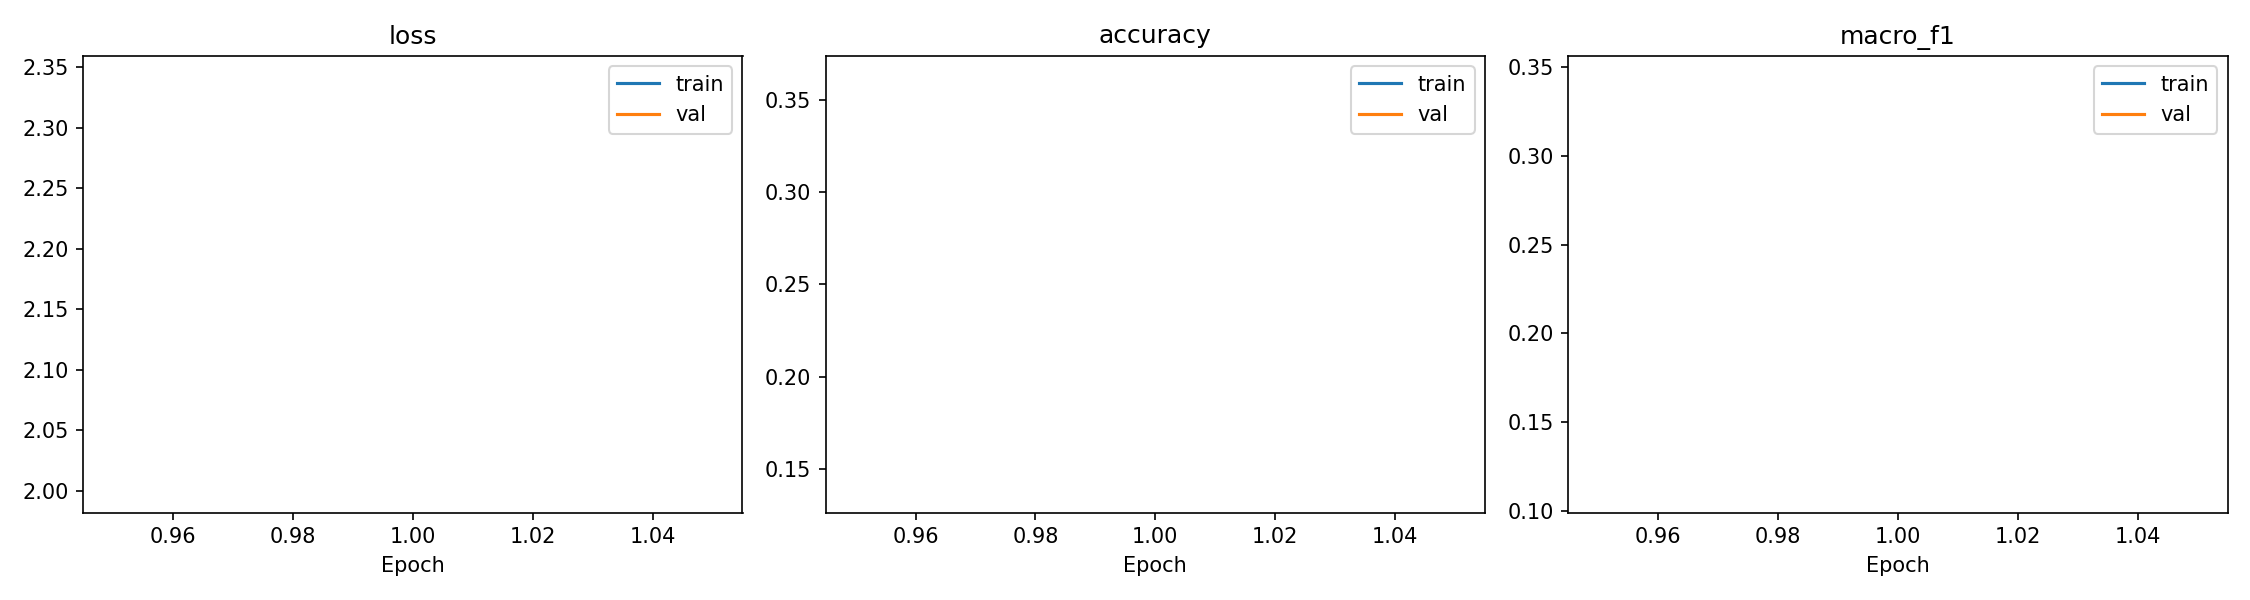

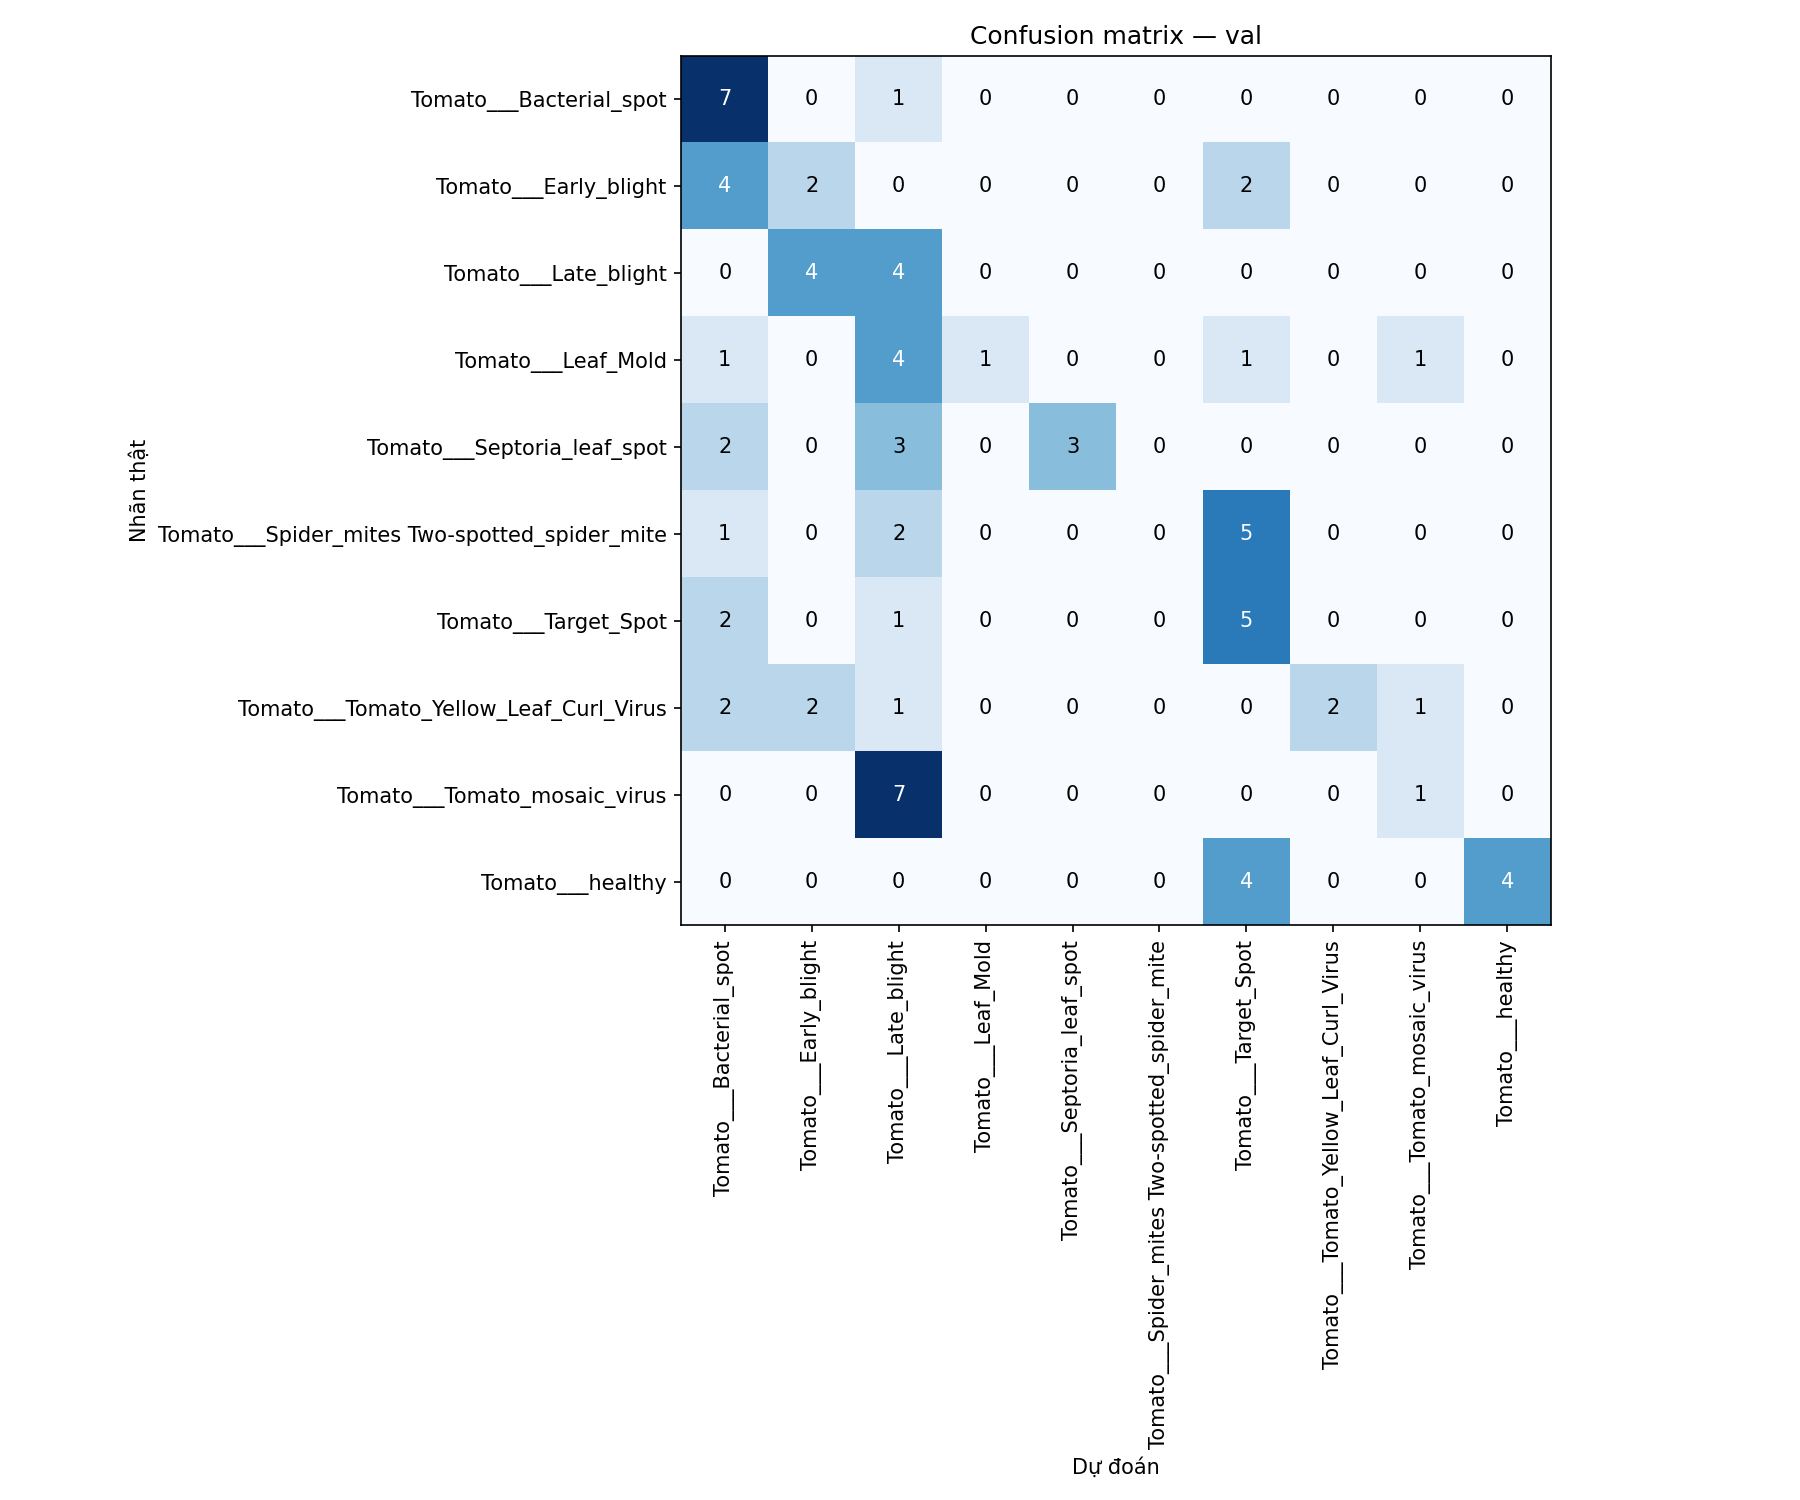

Smoke thành công. Hãy rà soát dữ liệu trước khi bật full training.


In [6]:
from leaf_training.train import configure_stage, make_loader, run_epoch

SMOKE_OK = False
smoke_records = subset_for_smoke(records, per_class=8, seed=42)
smoke_config = TrainConfig(epochs=1, warmup_epochs=1, batch_size=16, workers=0, smoke=True)
SMOKE_RUN = RUNS_ROOT / f"smoke-{datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')}"
train(DATA_ROOT, smoke_records, SMOKE_RUN, smoke_config, provenance=PROVENANCE)
smoke_metrics, smoke_report = evaluate(DATA_ROOT, smoke_records, SMOKE_RUN, split="val")
print(json.dumps(smoke_metrics, indent=2))
print(json.dumps(smoke_report, indent=2))
predictor = Predictor(SMOKE_RUN)
print(predictor.predict(DATA_ROOT / smoke_records[0]["path"], source="plantvillage_smoke"))
display(DisplayImage(filename=str(SMOKE_RUN / "history.png")))
display(DisplayImage(filename=str(SMOKE_RUN / "val_confusion_matrix.png")))

probe_config = TrainConfig(epochs=1, warmup_epochs=0, batch_size=10, workers=0, smoke=True)
optimizer, frozen = configure_stage(predictor.model, probe_config, 0)
scaler = torch.amp.GradScaler("cuda", enabled=True)
probe_rows = [next(r for r in smoke_records if r["split"] == "train" and r["label"] == label)
              for label in range(10)]
probe_metrics, _, _ = run_epoch(predictor.model,
    make_loader(DATA_ROOT, probe_rows, probe_config, True), predictor.device,
    torch.nn.CrossEntropyLoss(), scaler, optimizer, frozen)
assert any(p.grad is not None and torch.isfinite(p.grad).all() and p.grad.abs().sum() > 0
           for p in predictor.model.features.parameters())
SMOKE_OK = True
write_json(SMOKE_RUN / "smoke_success.json", {
    "fine_tune_probe": probe_metrics, "split_fingerprint": split_fingerprint,
    "passed_at": datetime.now(timezone.utc).isoformat(),
})
del predictor, optimizer, scaler
torch.cuda.empty_cache()
print("Smoke thành công. Hãy rà soát dữ liệu trước khi bật full training.")


## 7. Huấn luyện đầy đủ — mặc định tắt

Chỉ bật hai cờ sau smoke thành công và rà soát audit/phân bố/giới hạn leaf ID.
Khởi tạo lại ImageNet pretrained; không dùng weights smoke. Đóng băng backbone 2 epoch,
sau đó fine-tune, tối đa 20 epoch. Best theo Validation Macro F1, early stopping patience 5.
`last.pt` và `best.pt` ghi vào Google Drive mỗi epoch; giữ nguyên cả thư mục run để resume.


Epoch 1/20 (head): loss=0.5472; val_loss=0.2763; val_macro_f1=0.8557
Epoch 2/20 (head): loss=0.2583; val_loss=0.2345; val_macro_f1=0.8834
Epoch 3/20 (finetune): loss=0.2896; val_loss=0.1223; val_macro_f1=0.9525
Epoch 4/20 (finetune): loss=0.0873; val_loss=0.0640; val_macro_f1=0.9690
Epoch 5/20 (finetune): loss=0.0519; val_loss=0.0333; val_macro_f1=0.9850
Epoch 6/20 (finetune): loss=0.0312; val_loss=0.0361; val_macro_f1=0.9829
Epoch 7/20 (finetune): loss=0.0262; val_loss=0.0333; val_macro_f1=0.9864
Epoch 8/20 (finetune): loss=0.0274; val_loss=0.0317; val_macro_f1=0.9868
Epoch 9/20 (finetune): loss=0.0212; val_loss=0.0207; val_macro_f1=0.9893
Epoch 10/20 (finetune): loss=0.0124; val_loss=0.0149; val_macro_f1=0.9960
Epoch 11/20 (finetune): loss=0.0134; val_loss=0.0286; val_macro_f1=0.9892
Epoch 12/20 (finetune): loss=0.0096; val_loss=0.0218; val_macro_f1=0.9907
Epoch 13/20 (finetune): loss=0.0154; val_loss=0.0230; val_macro_f1=0.9928
Epoch 14/20 (finetune): loss=0.0171; val_loss=0.0143; v

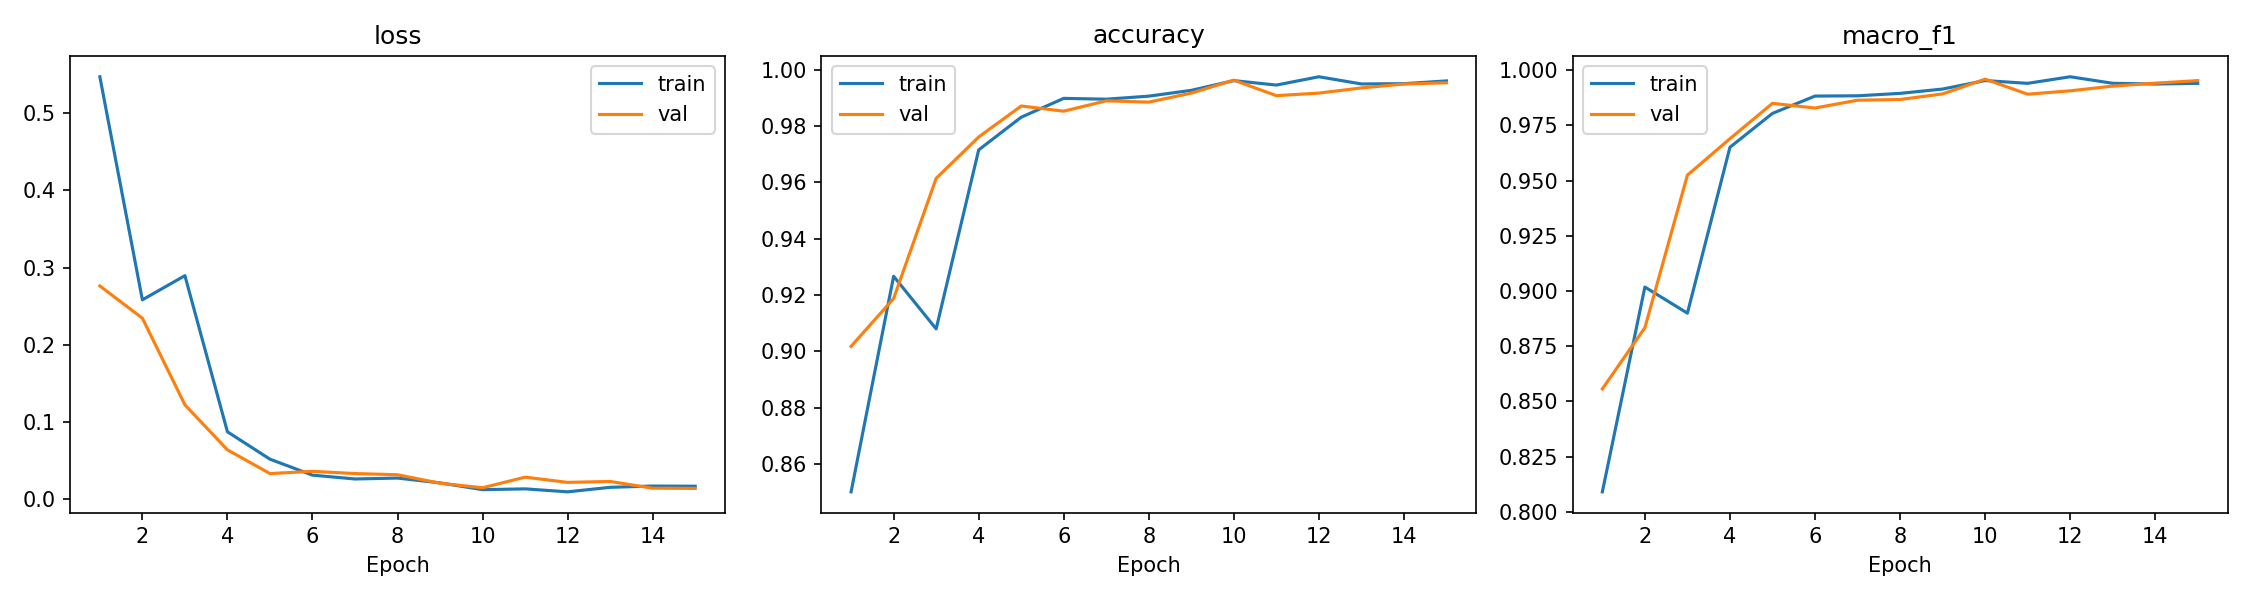

In [7]:
RUN_FULL_TRAINING = True
DATA_REVIEWED = True
full_config = TrainConfig(epochs=20, warmup_epochs=2, batch_size=32, workers=2)
if RUN_FULL_TRAINING:
    if not SMOKE_OK or not DATA_REVIEWED:
        raise RuntimeError("Cần smoke thành công và xác nhận đã rà soát dữ liệu.")
    FULL_RUN = RUNS_ROOT / f"mobilenetv3-{datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')}"
    train(DATA_ROOT, records, FULL_RUN, full_config, provenance=PROVENANCE)
    validation_metrics, validation_report = evaluate(DATA_ROOT, records, FULL_RUN, split="val")
    print(json.dumps(validation_metrics, indent=2))
    print(json.dumps(validation_report, indent=2))
    display(DisplayImage(filename=str(FULL_RUN / "history.png")))
else:
    print("Full training đang tắt.")


## 8. Resume sau khi runtime ngắt (tùy chọn)

Chạy lại bước 1–3, tải đúng dataset version, rồi chạy cell này với tên run cũ.
Dùng manifest đã lưu và kiểm tra SHA256 từng ảnh. Không cần chạy lại smoke nếu tiếp tục
run đã xác nhận. Resume từ epoch hoàn tất gần nhất, epoch đang dở chạy lại từ đầu.
Kiểm tra checkpoint đã ghi xong trước khi chủ động ngắt runtime; Drive có thể chưa đồng bộ nếu mất kết nối.


In [ ]:
RESUME_TRAINING = False
RESUME_RUN = RUNS_ROOT / "dien-ten-run-cu"
if RESUME_TRAINING:
    import hashlib
    resumed_metadata = json.loads((RESUME_RUN / "metadata.json").read_text(encoding="utf-8"))
    records = json.loads((RESUME_RUN / "manifest.json").read_text(encoding="utf-8"))
    for row in records:
        if hashlib.sha256((DATA_ROOT / row["path"]).read_bytes()).hexdigest() != row["sha256"]:
            raise ValueError(f"Dataset đã thay đổi: {row['path']}")
    full_config = TrainConfig(**resumed_metadata["config"])
    train(DATA_ROOT, records, RESUME_RUN, full_config, resume=True,
          provenance=resumed_metadata["provenance"])
    FULL_RUN = RESUME_RUN
    print(evaluate(DATA_ROOT, records, FULL_RUN, split="val")[0])


## 9. Đánh giá Test một lần sau khi chốt cấu hình

Không dùng Test điều chỉnh hyperparameter hoặc chọn model. Run đã có test_metrics.json
sẽ từ chối đánh giá lại; đọc báo cáo cũ. PlantVillage chưa đại diện ảnh ESP32-CAM thực tế.


{
  "loss": 0.015039842610295798,
  "accuracy": 0.9935661764705882,
  "precision_macro": 0.9902485755995546,
  "recall_macro": 0.9928802282142388,
  "macro_f1": 0.9915210071803828
}
{
  "Tomato___Bacterial_spot": {
    "precision": 0.9845559845559846,
    "recall": 1.0,
    "f1-score": 0.9922178988326849,
    "support": 255.0
  },
  "Tomato___Early_blight": {
    "precision": 0.9830508474576272,
    "recall": 0.9666666666666667,
    "f1-score": 0.9747899159663865,
    "support": 120.0
  },
  "Tomato___Late_blight": {
    "precision": 1.0,
    "recall": 0.9824561403508771,
    "f1-score": 0.9911504424778761,
    "support": 228.0
  },
  "Tomato___Leaf_Mold": {
    "precision": 0.9827586206896551,
    "recall": 1.0,
    "f1-score": 0.991304347826087,
    "support": 114.0
  },
  "Tomato___Septoria_leaf_spot": {
    "precision": 0.9952830188679245,
    "recall": 0.9952830188679245,
    "f1-score": 0.9952830188679245,
    "support": 212.0
  },
  "Tomato___Spider_mites Two-spotted_spider_mite

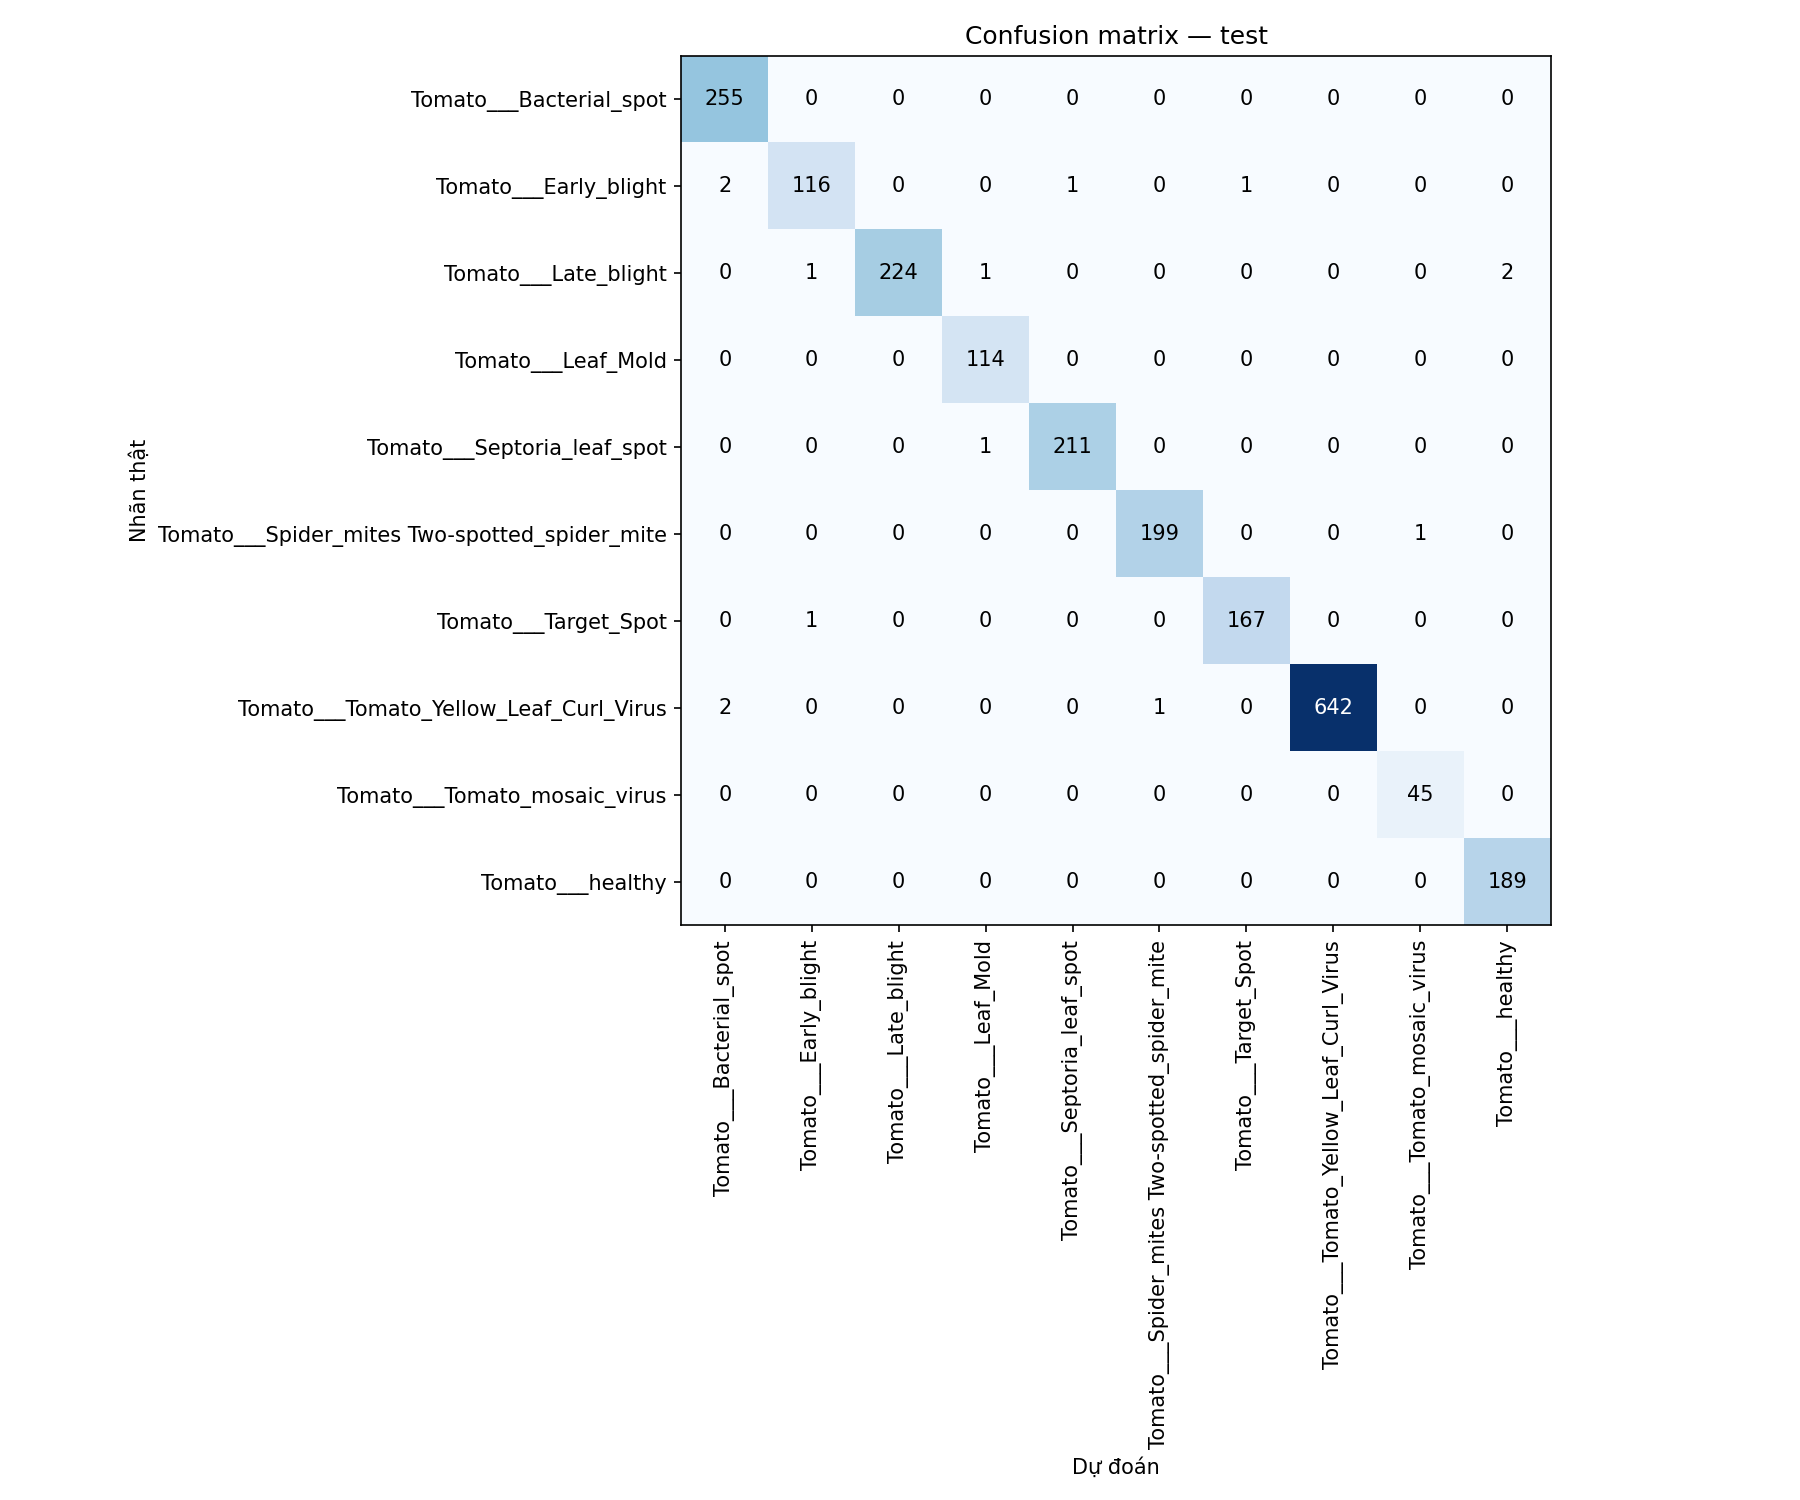

In [9]:
FINAL_EVALUATION = True
if FINAL_EVALUATION:
    if FULL_RUN is None:
        raise RuntimeError("Chưa có run đầy đủ; cần huấn luyện hoặc resume trước.")
    test_metrics, test_report = evaluate(DATA_ROOT, records, FULL_RUN, split="test", allow_test=True)
    print(json.dumps(test_metrics, indent=2))
    print(json.dumps(test_report, indent=2))
    display(DisplayImage(filename=str(FULL_RUN / "test_confusion_matrix.png")))
else:
    print("Test đang khóa; chỉ dùng Validation để chọn cấu hình.")


## 10. Inference trên ảnh mới và lấy artifact

Đặt ảnh trên Drive và điền NEW_IMAGE. Dùng run đầy đủ cho đánh giá thực tế;
smoke chỉ kiểm tra thao tác. Softmax chưa calibration, chưa có phát hiện ảnh ngoài phạm vi.
Artifact đã ở Google Drive: best.pt, class_mapping.json, preprocessing.json, metadata.json,
manifest.json, environment.txt, history và các báo cáo. Giữ last.pt để resume, không commit Git.


{'model_version': 'mobilenetv3-20261015T031708_509896Z', 'source': 'manual', 'model_source': 'trained', 'smoke_only': False, 'predicted_at': '2026-10-15T03:48:13.654318+00:00', 'label': 'Tomato___Late_blight', 'confidence': 0.9999934434890747, 'top_k': [{'class_name': 'Tomato___Late_blight', 'confidence': 0.9999934434890747}, {'class_name': 'Tomato___Early_blight', 'confidence': 4.130347406317014e-06}, {'class_name': 'Tomato___healthy', 'confidence': 9.798392284210422e-07}]}


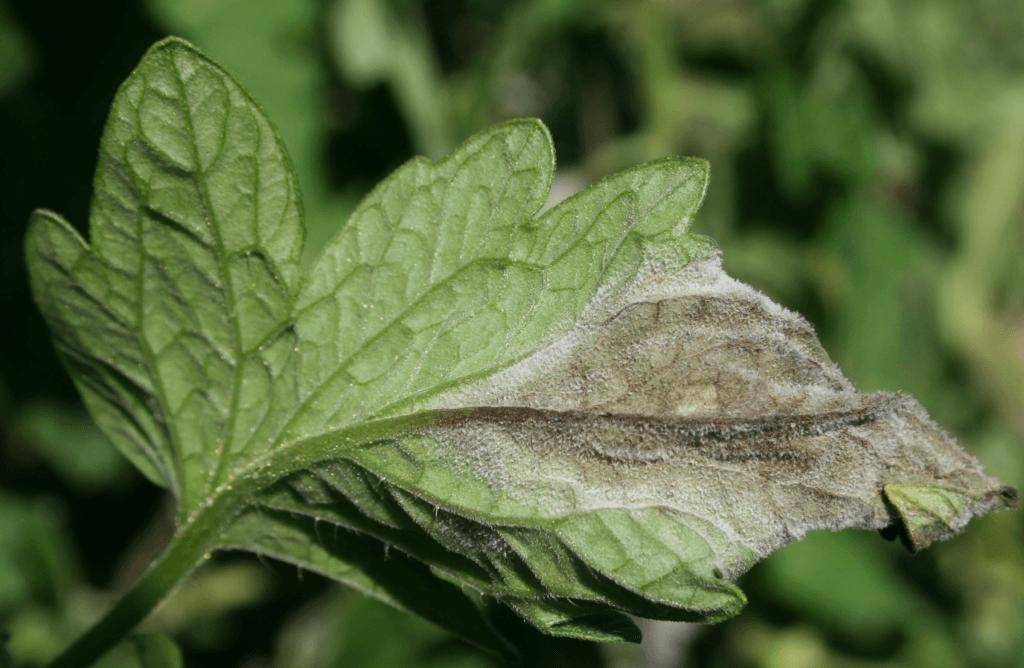

In [10]:
NEW_IMAGE = DRIVE_ROOT / "test-late-blight.jpg"
if NEW_IMAGE is not None:
    ARTIFACT_DIR = FULL_RUN if FULL_RUN is not None else SMOKE_RUN
    predictor = Predictor(ARTIFACT_DIR)
    print(predictor.predict(NEW_IMAGE, source="manual"))
    display(DisplayImage(filename=str(NEW_IMAGE)))
